# Explicabilidad con SHAP — Churn (cancelación de pólizas)

**Diplomado ML en Seguros · Plus: interpretabilidad de modelos**

Entrenamos un modelo que predice si un cliente **cancela su póliza (churn)** y usamos **SHAP**
para explicar *por qué*: qué variables empujan la decisión, en todo el modelo (global) y para
**un cliente concreto** (local). Al final lanzamos **Shapash**, una app de explicabilidad lista
para usar.

> Dataset didáctico `churn_seguros.csv` — ya viene listo, no hay que limpiar nada.


In [2]:
!pip install category_encoders

In [3]:
import numpy as np, pandas as pd
import shap
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
import category_encoders as ce
import warnings; warnings.filterwarnings("ignore")
shap.initjs()

## 1 · Los datos

In [4]:
df = pd.read_csv("churn_seguros.csv")
print("Filas:", len(df), "| Tasa de churn:", round(df['churn'].mean(), 3))
df.head()

Filas: 5000 | Tasa de churn: 0.223


,antiguedad,siniestros,incr_prima,descuento,quejas,edad,canal,pago,multiproducto,competidor_barato,churn
0,2,1,13.2,0,1,48,Online,Manual,1,0,1
1,2,0,10.5,0,0,34,Telefono,Manual,0,0,0
2,15,0,8.6,5,0,40,Telefono,Manual,1,1,0
3,9,1,30.2,5,0,30,Agente,Domiciliado,0,0,0
4,11,0,8.3,5,0,59,Online,Domiciliado,0,1,0


## 2 · El modelo

Un **Random Forest** (modelo de árboles). SHAP funciona con cualquier modelo, pero con árboles es
**rápido y exacto** (`TreeExplainer`).

In [5]:
CATS = ["canal", "pago"]
X = df.drop(columns="churn"); y = df["churn"]
enc = ce.OrdinalEncoder(cols=CATS).fit(X)          # codifica categóricas a números
Xe = enc.transform(X)
Xtr, Xte, ytr, yte = train_test_split(Xe, y, test_size=0.25, random_state=0)
model = RandomForestClassifier(n_estimators=200, max_depth=7, random_state=0).fit(Xtr, ytr)
print("Exactitud en test:", round(model.score(Xte, yte), 3))

Exactitud en test: 0.79


## 3 · SHAP: valores de contribución

SHAP reparte la predicción entre las variables: cuánto **empuja cada una** hacia “cancela” o
“se queda”, para cada cliente.

In [6]:
explainer = shap.TreeExplainer(model)
sv = explainer(Xte)
sv1 = sv[:, :, 1] if sv.values.ndim == 3 else sv     # clase churn = 1
print("Matriz de valores SHAP:", sv1.values.shape)

Matriz de valores SHAP: (1250, 10)


### 3.1 Global — beeswarm
Cada punto es un cliente. A la derecha = empuja a **cancelar**. El color es el valor de la variable
(rojo alto, azul bajo).

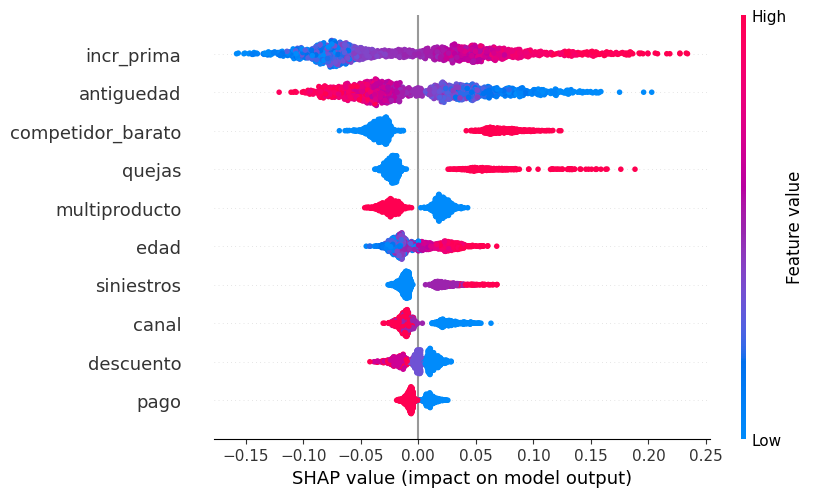

In [7]:
shap.plots.beeswarm(sv1, max_display=10)

### 3.2 Global — importancia (barras)
La magnitud promedio del impacto de cada variable.

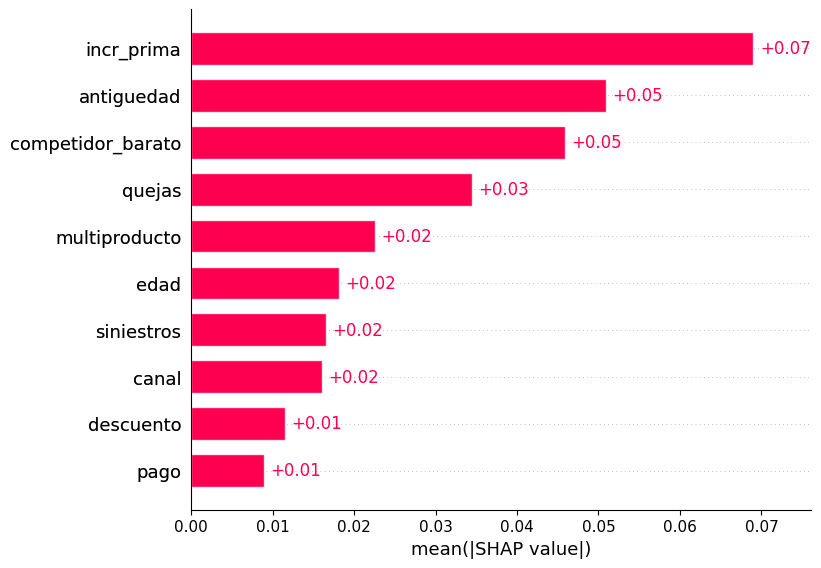

In [8]:
shap.plots.bar(sv1, max_display=10)

### 3.3 Local — ¿por qué ESTE cliente?
El *waterfall* descompone la predicción de **un cliente**: desde el valor base hasta su predicción,
sumando el empuje de cada variable. Es la versión general del “¿por qué esta prima?” del pricing,
para **cualquier** modelo.

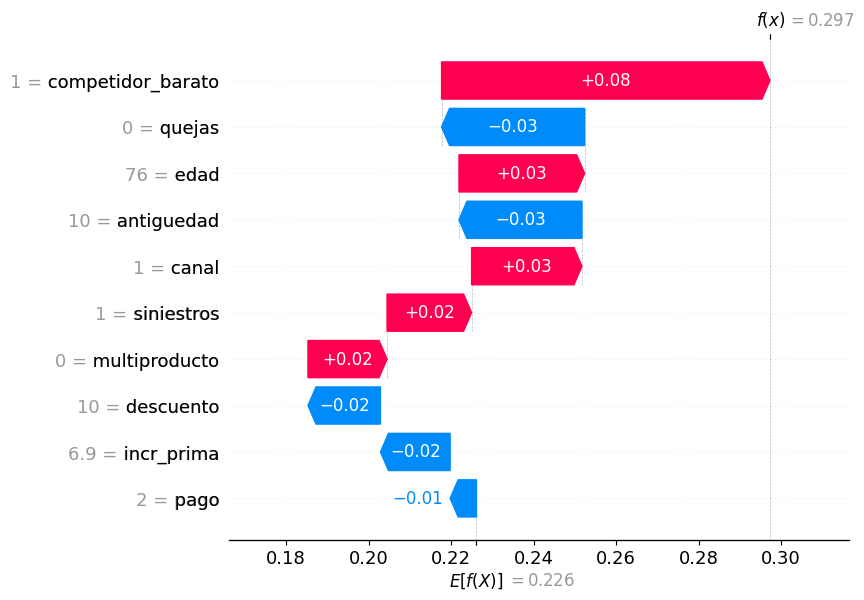

In [9]:
shap.plots.waterfall(sv1[0], max_display=10)

### 3.4 Dependence — cómo actúa una variable
Efecto del incremento de prima sobre el churn.

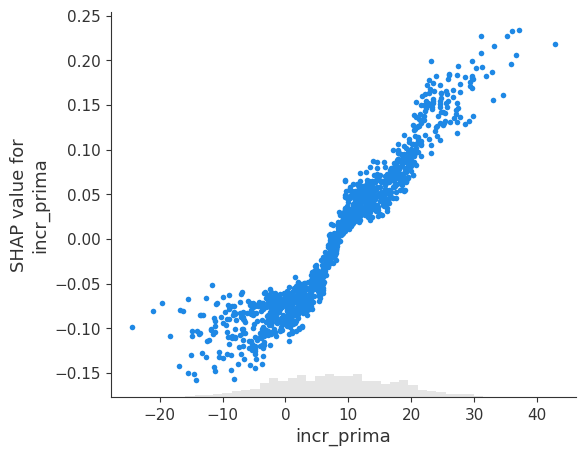

In [10]:
shap.plots.scatter(sv1[:, "incr_prima"])

## 4 · Shapash — la app de explicabilidad, lista para usar

Shapash se construye **sobre SHAP** y te arma un **dashboard** sin que programes la interfaz.
Le pasas el modelo (y opcionalmente etiquetas bonitas) y compila.

In [12]:
!pip install shapash

   ---------------------------------------- 0.0/13.1 MB ? eta -:--:--
   --- ------------------------------------ 1.0/13.1 MB ? eta -:--:--
   --- ------------------------------------ 1.0/13.1 MB ? eta -:--:--
   ------- -------------------------------- 2.4/13.1 MB 3.4 MB/s eta 0:00:04
   ---------------- ----------------------- 5.2/13.1 MB 6.5 MB/s eta 0:00:02
   ---------------------- ----------------- 7.3/13.1 MB 7.1 MB/s eta 0:00:01
   ---------------------------- ----------- 9.4/13.1 MB 7.8 MB/s eta 0:00:01
   -------------------------------- ------- 10.5/13.1 MB 8.1 MB/s eta 0:00:01
   ----------------------------------- ---- 11.5/13.1 MB 7.2 MB/s eta 0:00:01
   ---------------------------------------- 13.1/13.1 MB 7.1 MB/s  0:00:01
   ---------------------------------------- 0.0/7.9 MB ? eta -:--:--
   --------------- ------------------------ 3.1/7.9 MB 16.8 MB/s eta 0:00:01
   ---------------------------------- ----- 6.8/7.9 MB 16.1 MB/s eta 0:00:01
   -------------------------

In [13]:
from shapash import SmartExplainer
fdict = {"antiguedad":"Antigüedad (años)","siniestros":"Nº siniestros","incr_prima":"Incremento de prima (%)",
         "descuento":"Descuento (%)","quejas":"Nº quejas","edad":"Edad","canal":"Canal",
         "pago":"Método de pago","multiproducto":"Multiproducto","competidor_barato":"Competidor más barato"}
xpl = SmartExplainer(model=model, preprocessing=enc, features_dict=fdict)
xpl.compile(x=Xte, y_pred=pd.Series(model.predict(Xte), index=Xte.index))
print("Shapash compilado.")

INFO: Shap explainer type - <shap.explainers._tree.TreeExplainer object at 0x0000028471A96650>
Shapash compilado.


### 4.1 Gráficas de Shapash (interactivas)

In [14]:
xpl.plot.features_importance()

In [15]:
xpl.plot.local_plot(index=Xte.index[0])      # explicación de un cliente

### 4.2 Lanzar la app

Esto abre un **dashboard web** (Dash) donde puedes explorar cliente por cliente, filtrar y ver las
contribuciones. Córrelo en tu máquina:

In [ ]:
app = xpl.run_app(title_story="Churn de pólizas", host="0.0.0.0", port=8050)
# Abre http://localhost:8050  ·  para detenerlo:  app.kill()

INFO:root:Your Shapash application run on http://0.0.0.0:8050/
INFO:root:Use the method .kill() to down your app.


INFO:werkzeug:127.0.0.1 - - [27/Oct/2026 13:49:38] "GET / HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [27/Oct/2026 13:49:38] "GET /assets/material-icons.css?m=1793130526.011652 HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [27/Oct/2026 13:49:38] "GET /assets/style.css?m=1793130526.015769 HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [27/Oct/2026 13:49:38] "GET /_dash-component-suites/dash/deps/polyfill@7.v3_4_0m1793130524.12.1.min.js HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [27/Oct/2026 13:49:38] "GET /_dash-component-suites/dash/deps/react@18.v3_4_0m1793130524.3.1.min.js HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [27/Oct/2026 13:49:38] "GET /_dash-component-suites/dash/deps/react-dom@18.v3_4_0m1793130524.3.1.min.js HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [27/Oct/2026 13:49:38] "GET /_dash-component-suites/dash/deps/prop-types@15.v3_4_0m1793130524.8.1.min.js HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [27/Oct/2026 13:49:38] "GET /_dash-component-suites/dash_bootstrap_components/_co

In [17]:
app.kill()

## 5 · ¿Y con Streamlit?

También puedes incrustar SHAP en una app de **Streamlit** con el componente `streamlit-shap`
(`st_shap(shap.plots.waterfall(...))`). Shapash es lo más rápido (app lista); Streamlit te da
control total — eso ya depende de ustedes.
